In [1]:
%pip install pandas numpy scikit_learn xgboost


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier # use for tabular data  and strong predictions tasks
# different than the logistic regression, instead of one mathematical formula,
#it  builds many decision trees, one after another, each focus on fixing the mistakes previous trees made.
from sklearn.utils.class_weight import compute_sample_weight # compute weights for each class to handle class imbalance
from sklearn.metrics import (classification_report, f1_score, confusion_matrix, precision_recall_fscore_support) # measure how well predictions model performs.
# classification_report gives precision, recall, F1-score, and support for each class.
#f1_score computes the F1 score, useful when class imbalance is present.


In [3]:
# loading the cleaned data from Data_Prep.ipynb

x_train_structured = pd.read_csv("x_train_clean.csv")
y_train_clean = pd.read_csv("y_train_clean.csv").squeeze().astype(int)

x_test_structured = pd.read_csv("x_test_clean.csv")
y_test = pd.read_csv("y_test_clean.csv").squeeze().astype(int)
test_stay_ids = x_test_structured["stay_id"].to_numpy()

print(x_train_structured.shape, x_test_structured.shape, y_train_clean.shape, y_test.shape)
print("Patient overlap:", len(set(x_train_structured["subject_id_x"]) & set(x_test_structured["subject_id_x"])), "(expect 0)")

(334480, 63) (83620, 63) (334480,) (83620,)
Patient overlap: 0 (expect 0)


In [4]:
#preparing the structured data for the model by removing the text column.

#Creates x_train_structured from the training data but removes the columns_to_drop columns.

columns_to_drop = ['chiefcomplaint', 'subject_id_x', 'subject_id_y', 'stay_id', 'hadm_id', 'intime', 'outtime', 'disposition']

x_train_structured = x_train_structured.drop(columns=columns_to_drop)
x_test_structured = x_test_structured.drop(columns=columns_to_drop)
#  no errors='ignore': a typo should fail loudly
print(x_train_structured.shape, x_test_structured.shape)


#Displays the size of both datasets after columns drop: Number of rows and columns


(334480, 55) (83620, 55)


In [5]:
#converting the pain column from text values into numbers:

x_train_structured['pain'] = pd.to_numeric(x_train_structured['pain'], errors='coerce')
#x_train_structured['pain'] selects the training dataset’s pain column.
#pd.to_numeric() attempts to convert values such as "5" into numeric values such as 5.

x_test_structured['pain'] = pd.to_numeric(x_test_structured['pain'], errors='coerce')

print("Text columns left:", list(x_train_structured.dtypes[x_train_structured.dtypes == 'object'].index), "(expect [])")
print("Pain columns:", [c for c in x_train_structured.columns if c.startswith("pain")])
print("Same columns in train and test:", list(x_train_structured.columns) == list(x_test_structured.columns))
#errors='coerce' changes values that cannot be converted, such as "unknown" or empty text, into NaN,
# which XGBoost handle them automatically.

Text columns left: [] (expect [])
Pain columns: ['pain', 'pain_empty', 'pain_unable', 'pain_odd']
Same columns in train and test: True


In [6]:
#checking whether any columns in x_train_structured still contain text values:

x_train_structured.dtypes[x_train_structured.dtypes == 'object']

#x_train_structured.dtypes[......] Filters the result and displays only those object-type columns.
# In Pandas object means the columns that have text or mixed values

Series([], dtype: object)

In [7]:
# RE-labelling the y for XGBoost
#XGBoost expect multiclass labels to start at 0 and end at num_class - 1. 
# so the label are 0,1,2,3, 4 since num_class=5 in cell 17
y_train_xgb = y_train_clean - 1
y_test_xgb = y_test - 1


In [8]:
# Creating and training the XGBoost classification model.
# During training, XGBoost builds decision trees that learn relationships between the structured patient data and the target classes.

model_xgb = XGBClassifier(     #  creates an XGBoost model for classification.
    objective='multi:softmax', # tells XGBoost that this is a multiclass problem and it should directly return the predicted class.
    num_class=5,               # tells the model there are five possible classes: 0, 1, 2, 3, 4.
    eval_metric='mlogloss',    # specifies the metric used internally to evaluate multiclass prediction errors. Lower values are better.
    random_state=42            # makes the results reproducible when the code is run again.
)

model_xgb.fit(x_train_structured, y_train_xgb) # Trains the model

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import lo

In [9]:
# Making the predictions on the test set

predictions_xgb_shifted = model_xgb.predict(x_test_structured)

# make the predictions in 0-4 range


In [10]:
# Now shifting the predictions back to real ESI levels 1-5


predictions_xgb = (predictions_xgb_shifted + 1).astype(int)
# Earlier XGBoost changed label from 1-5 to 0-4 as XGBoost requires class labels to start at 0
# now shifting to the original ESi levels, allows us to compare them correctly with y_test.


In [11]:
# Evaluating

print(classification_report(y_test, predictions_xgb))

print("Macro F1:", f1_score(y_test, predictions_xgb, average='macro')
      )

c:\Users\harik\anaconda3\envs\aaih8801\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\harik\anaconda3\envs\aaih8801\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\harik\anaconda3\envs\aaih8801\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", res

              precision    recall  f1-score   support

           1       0.73      0.62      0.68      4804
           2       0.57      0.37      0.45     27882
           3       0.62      0.85      0.72     45013
           4       0.10      0.00      0.00      5701
           5       0.00      0.00      0.00       220

    accuracy                           0.62     83620
   macro avg       0.41      0.37      0.37     83620
weighted avg       0.57      0.62      0.58     83620

Macro F1: 0.36886446009898777


"""
Conclusion from above result

The dataset is imbalanced:
Class 3 has 45,013 examples.
Class 5 has only 220 examples.
The model achieves 61% accuracy mainly by performing well on the larger classes, especially ESI 3. It performs poorly on ESI 4 and ESI 5, 
so the macro F1-score gives a honest view of the model’s performance across all ESI levels.
"""

In [12]:
#training a second XGBoost model, but this time it tries to correct the class imbalance.
# since in cell 17 every training row gave equal importance:

sample_weights = y_train_xgb.map(y_train_xgb.value_counts(normalize=True).apply(lambda x:1/x))

# minority-class rows receive larger weights
#The model treats mistakes on the less common class as more important. This may improve predictions for ESI classes 4 and 5, which previously had very low recall.
# model_xgb_weighted: performance when errors on minority classes receive more importance.

model_xgb_weighted =XGBClassifier(   #creates a new model so the original unweighted model remains available for comparison.
    objective='multi:softmax',
    num_class= 5,
    eval_metric = 'mlogloss',
    random_state = 42
)

model_xgb_weighted.fit(x_train_structured, y_train_xgb, sample_weight= sample_weights)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import lo

In [13]:
predictions_xgb_shifted_wt = model_xgb_weighted.predict(x_test_structured)

In [14]:
predictions_xgb_wt = (predictions_xgb_shifted_wt + 1).astype(int)

In [15]:
print(classification_report(y_test, predictions_xgb_wt))
print("Macro F1:", f1_score(y_test, predictions_xgb_wt, average='macro'))

              precision    recall  f1-score   support

           1       0.55      0.69      0.61      4804
           2       0.51      0.52      0.51     27882
           3       0.67      0.26      0.37     45013
           4       0.14      0.55      0.22      5701
           5       0.01      0.48      0.02       220

    accuracy                           0.39     83620
   macro avg       0.37      0.50      0.35     83620
weighted avg       0.57      0.39      0.42     83620

Macro F1: 0.3484771864724459


"""
Conclusion
The weighted model is more balanced in terms of recall, but its predictions are less accurate overall.  Macro F1-score is:
0.348 weighted model
0.369 unweighted model
Therefore, based on macro F1, the weighted model did not improve overall performance across all five ESI classes.

The unweighted model has the better result numerically, but it almost completely ignores ESI 4 and ESI 5. 
The weighted model is better if identifying minority-class patients is more important than overall accuracy,
 but it needs further tuning to improve precision.
"""

In [16]:
#save both sets of predictions
import os
os.makedirs("results", exist_ok=True)
for fname, yp in (("structured_unweighted", predictions_xgb), ("structured_weighted", predictions_xgb_wt)):
    np.savez(f"results/{fname}.npz", y_true=y_test.values, y_pred=np.asarray(yp),
             stay_id=test_stay_ids)

In [17]:
# Saving the both result of weighted and unweighted

results = {}
results['XGBoost (unweighted)'] = {'macro_f1': 0.369}
results['XGBoost (class-weighted)'] = {'macro_f1': f1_score(y_test, predictions_xgb_wt, average='macro')}
results


{'XGBoost (unweighted)': {'macro_f1': 0.369},
 'XGBoost (class-weighted)': {'macro_f1': 0.3484771864724459}}

In [18]:
# saving  both results with their details
# Saves the metrics for the normal XGBoost model 

report_xgb_unweighted = classification_report(
    y_test, predictions_xgb, output_dict=True, labels=[1,2,3,4,5], zero_division=0
)

results['XGBoost (unweighted)'] = {
    'macro_f1': f1_score(y_test, predictions_xgb, average='macro'),
    'recall_esi4': report_xgb_unweighted['4']['recall'],
    'recall_esi5': report_xgb_unweighted['5']['recall'],
}

#Saves the same metrics for the weighted XGBoost model
report_xgb_weighted = classification_report(
    y_test, predictions_xgb_wt, output_dict=True, labels=[1,2,3,4,5], zero_division=0
)

results['XGBoost (class-weighted)'] = {
    'macro_f1': f1_score(y_test, predictions_xgb_wt, average='macro'),
    'recall_esi4': report_xgb_weighted['4']['recall'],
    'recall_esi5': report_xgb_weighted['5']['recall'],
}

results

{'XGBoost (unweighted)': {'macro_f1': 0.36886446009898777,
  'recall_esi4': 0.00017540782318891423,
  'recall_esi5': 0.0},
 'XGBoost (class-weighted)': {'macro_f1': 0.3484771864724459,
  'recall_esi4': 0.5534116821610244,
  'recall_esi5': 0.4818181818181818}}

### Optional data and leakage checks
The three cells below verify the train/test split and model features. They do not train the model.

In [19]:
# reloading the raw train/test files and checking their shapes and whether the two subject ID columns match.
import pandas as pd

raw_train = pd.read_csv("x_train_clean.csv")
raw_test  = pd.read_csv("x_test_clean.csv")

print("Train:", raw_train.shape, "| Test:", raw_test.shape)
print("subject_id_x present:", "subject_id_x" in raw_train.columns)
print("subject_id_x and _y identical:",
      (raw_train["subject_id_x"] == raw_train["subject_id_y"]).all())

Train: (334480, 63) | Test: (83620, 63)
subject_id_x present: True
subject_id_x and _y identical: True


In [20]:
# checking whether any patients appear in both the training and test sets. 
# This is important: patient overlap can make test results look better than they really are.
train_ids = set(raw_train["subject_id_x"])
test_ids  = set(raw_test["subject_id_x"])
overlap   = train_ids & test_ids

print("Unique patients in train:", len(train_ids))
print("Unique patients in test :", len(test_ids))
print("Patients in BOTH        :", len(overlap))
print("Share of test rows from patients also in train: "
      f"{raw_test['subject_id_x'].isin(overlap).mean():.1%}")

Unique patients in train: 161001
Unique patients in test : 40251
Patients in BOTH        : 0
Share of test rows from patients also in train: 0.0%


In [21]:
#This cell is a feature audit.
#  It does not train the model or change your data; it prints which columns the model may use and checks whether certain risky columns are present.

leak_cols = ["hadm_id", "outtime", "disposition",        # leak_cols lists identifiers and information that could cause leakage, such as disposition or outtime, which may only be known after triage.
             "subject_id_x", "subject_id_y", "stay_id",  # identifiers
             "intime"]                                    # timestamp

features_used = list(x_train_structured.columns) #features_used gets the column names currently in
#The print statements show the feature count, any listed risky columns still being used, and the complete feature list.

print("Number of features used:", len(features_used))
print("Leak/identifier columns used as features:",
      [c for c in features_used if c in leak_cols])
print("Not used (good):", [c for c in leak_cols if c not in features_used])
print("\nAll features:", features_used)

Number of features used: 55
Leak/identifier columns used as features: []
Not used (good): ['hadm_id', 'outtime', 'disposition', 'subject_id_x', 'subject_id_y', 'stay_id', 'intime']

All features: ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'gender', 'heartrate_missing', 'temperature_missing', 'sbp_missing', 'dbp_missing', 'resprate_missing', 'o2sat_missing', 'pain_empty', 'pain_unable', 'pain_odd', 'race_AMERICAN INDIAN/ALASKA NATIVE', 'race_ASIAN', 'race_ASIAN - ASIAN INDIAN', 'race_ASIAN - CHINESE', 'race_ASIAN - KOREAN', 'race_ASIAN - SOUTH EAST ASIAN', 'race_BLACK/AFRICAN', 'race_BLACK/AFRICAN AMERICAN', 'race_BLACK/CAPE VERDEAN', 'race_BLACK/CARIBBEAN ISLAND', 'race_HISPANIC OR LATINO', 'race_HISPANIC/LATINO - CENTRAL AMERICAN', 'race_HISPANIC/LATINO - COLUMBIAN', 'race_HISPANIC/LATINO - CUBAN', 'race_HISPANIC/LATINO - DOMINICAN', 'race_HISPANIC/LATINO - GUATEMALAN', 'race_HISPANIC/LATINO - HONDURAN', 'race_HISPANIC/LATINO - MEXICAN', 'race_HISPANIC/LAT

XGBoost (unweighted)       macro F1 = 0.3689
XGBoost (class-weighted)   macro F1 = 0.3485


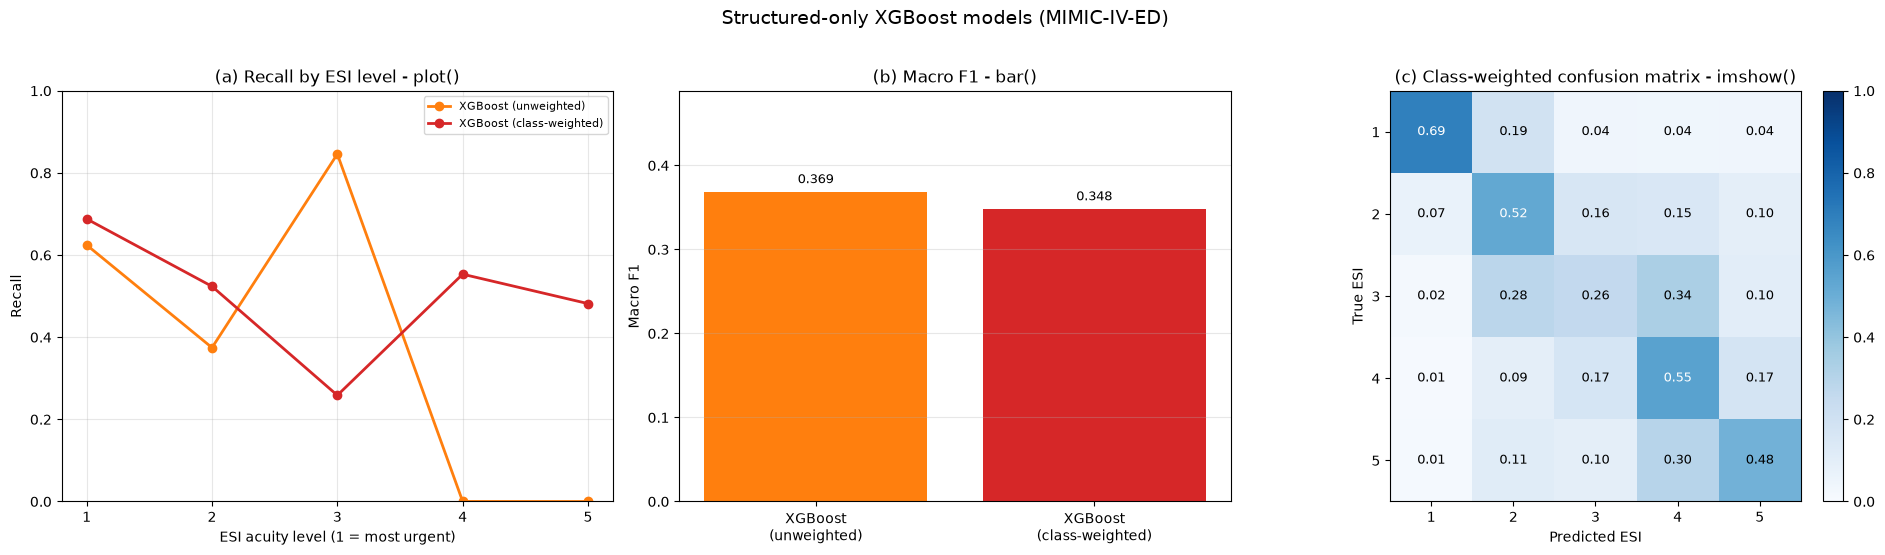

In [22]:
#the three figures (plot, bar, imshow) 

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, f1_score, confusion_matrix
 
ESI = [1, 2, 3, 4, 5]
runs = {"XGBoost (unweighted)": np.asarray(predictions_xgb),
        "XGBoost (class-weighted)": np.asarray(predictions_xgb_wt)}
colours = {"XGBoost (unweighted)": "tab:orange", "XGBoost (class-weighted)": "tab:red"}
 
res = {}
for name, yp in runs.items():
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, labels=ESI, zero_division=0)
    res[name] = {"recall": r, "macro_f1": f1_score(y_test, yp, average="macro")}
    print(f"{name:26s} macro F1 = {res[name]['macro_f1']:.4f}")
 
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))
 
ax = axes[0]                                                    # (a) plot()
for name, r in res.items():
    ax.plot(ESI, r["recall"], marker="o", linewidth=2, label=name, color=colours[name])
ax.set_xticks(ESI); ax.set_ylim(0, 1)
ax.set_xlabel("ESI acuity level (1 = most urgent)"); ax.set_ylabel("Recall")
ax.set_title("(a) Recall by ESI level - plot()"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
 
ax = axes[1]                                                    # (b) bar()
vals = [r["macro_f1"] for r in res.values()]
bars = ax.bar([n.replace(" (", "\n(") for n in res], vals, color=[colours[n] for n in res])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("Macro F1"); ax.set_ylim(0, max(vals) + 0.12)
ax.set_title("(b) Macro F1 - bar()"); ax.grid(axis="y", alpha=0.3)
 
ax = axes[2]                                                    # (c) imshow(): class-weighted confusion matrix
cm = confusion_matrix(y_test, runs["XGBoost (class-weighted)"], labels=ESI, normalize="true")
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(ESI); ax.set_yticks(range(5)); ax.set_yticklabels(ESI)
ax.set_xlabel("Predicted ESI"); ax.set_ylabel("True ESI")
ax.set_title("(c) Class-weighted confusion matrix - imshow()")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
 
plt.suptitle("Structured-only XGBoost models (MIMIC-IV-ED)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("Figure_Structured_Model_B.png", dpi=300, bbox_inches="tight")
plt.show()
 

This figure compares two structured-data XGBoost models: unweighted(orange) and class-weighted (red). ESI 1 is the most urgent category; ESI 5 is the least urgent.

(a) Recall by ESI level shows how often each model correctly identifies patients who truly belong to each ESI category. The unweighted model has zero recall for ESI 4 and 5, meaning it missed all test cases in those categories. The class-weighted model identifies some of them: recall is about 55% for ESI 4 and 48% for ESI 5. But it does worse on ESI 3: about 26% correct, compared with about 85% for the unweighted model.

(b) Macro F1 averages the F1 score across all five categories equally. The unweighted model scores 0.369, slightly above the weighted model’s 0.348. So the weighted model improves recall for ESI 4 and 5, but that improvement does not raise its overall macro F1.

(c) Confusion matrix shows the class-weighted model’s predictions. Rows are the actual ESI; columns are the predicted ESI. Each row adds to about 1, and the diagonal shows correct predictions. For example, 0.55 on the ESI 4 diagonal means it correctly identified about 55% of true ESI 4 cases. It often confuses nearby levels: 34% of true ESI 3 cases were predicted as ESI 4, and 30% of true ESI 5 cases were predicted as ESI 4.

Overall: the weighted model catches more ESI 4 and 5 cases, while the unweighted model scores slightly higher on macro F1 and does much better on ESI 3. The figure reports model performance on this test set; it is not evidence that either model is ready for clinical use.

In [ ]:
#This cell does a “hyperparameter tuning benchmark” for an XGBoost model.
# This cell is benchmarking whether tuning XGBoost actually improves performance over the default model, using the same 3 group-aware CV folds for fairness.

import os, time
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support
 
X_all = x_train_structured.to_numpy(dtype=float) # Convert training features to numpy array
y_all = y_train_xgb.to_numpy()  # Convert training labels to numpy array
groups_all = pd.read_csv("x_train_clean.csv", usecols=["subject_id_x"])["subject_id_x"].to_numpy()
assert len(groups_all) == len(X_all), "patient ids do not line up with the training rows" # ASSERTION: checks that the number of subject IDs matches the number of training rows. Each row in X_all corresponds to a patient visit, and groups_all contains the subject ID for each visit. This ensures that the grouping information is aligned with the training data.
 
N_SUB = min(100000, len(X_all))  # subsample the training data to speed up cross-validation. If the training set has fewer than 100,000 rows, use all of it.
N_ITER = 12
rng = np.random.default_rng(42)
idx = rng.choice(len(X_all), size=N_SUB, replace=False)
X_sub, y_sub, g_sub = X_all[idx], y_all[idx], groups_all[idx]
 
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)   # patients never split across folds
folds = list(cv.split(X_sub, y_sub, g_sub))
inv_sub = 1 / (np.bincount(y_sub, minlength=5) / len(y_sub))[y_sub]    # inverse class frequency per row
 
param_dist = {"max_depth": [3, 4, 6, 8], "learning_rate": [0.05, 0.1, 0.3],
              "n_estimators": [100, 200, 300], "min_child_weight": [1, 5, 10],
              "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 1.0],
              "reg_lambda": [1, 5, 10],
              "weight_power": [0.0, 0.25, 0.5, 0.75, 1.0]}
 
def cv_score(params, power):
    w = inv_sub ** power
    scores = []
    for tr, va in folds:
        m = XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42,
                          n_jobs=-1, **params)
        m.fit(X_sub[tr], y_sub[tr], sample_weight=w[tr])
        scores.append(f1_score(y_sub[va], m.predict(X_sub[va]), average="macro"))   # UNWEIGHTED, like the test
    return float(np.mean(scores)), float(np.std(scores))
 
candidates = [("default, class-weighted (power 1)", {}, 1.0),
              ("default, unweighted (power 0)", {}, 0.0)]
for p in ParameterSampler(param_dist, n_iter=N_ITER, random_state=42): # ParameterSampler(param_dist, n_iter=N_ITER, random_state=42) generates N_ITER random combinations of hyperparameters from the param_dist dictionary. Each combination is a dictionary of hyperparameter values. The random_state ensures that the same combinations are generated each time the code is run for reproducibility.
    p = dict(p)   # Convert the parameter combination to a dictionary
    power = p.pop("weight_power")    # Extract the weight_power parameter
    candidates.append(("random search", p, power))  # Add the candidate to the list
 
rows = []
for name, params, power in candidates:  # Iterate over each candidate hyperparameter configuration
    t0 = time.time()
    mean, sd = cv_score(params, power)
    rows.append({"candidate": name, "weight_power": power, **params,
                 "cv_macro_f1": round(mean, 4), "std": round(sd, 4)})
    print(f"{len(rows)}/{len(candidates)}  cv macro F1 = {mean:.4f}  ({(time.time() - t0) / 60:.1f} min)")
 
os.makedirs("results", exist_ok=True)
cv_table = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False) # Sort the cross-validation results by macro F1 score
cv_table.to_csv("results/tuning_cv_results_structured_v2.csv", index=False)
print(cv_table.head(6).to_string(index=False))
print("\nBoth defaults in this table:")
print(cv_table[cv_table["candidate"].str.startswith("default")][["candidate", "cv_macro_f1", "std"]].to_string(index=False))
 
best_idx = int(np.argmax([r["cv_macro_f1"] for r in rows])) # np.argmax([r["cv_macro_f1"] for r in rows]) finds the index of the candidate with the highest cross-validation macro F1 score. It creates a list of cv_macro_f1 scores from the rows and returns the index of the maximum value. This index is then converted to an integer and stored in best_idx, which is used to identify the best hyperparameter configuration from the candidates list.
best_name, best_params, best_power = candidates[best_idx]
print("\nBest:", best_name, best_params, "weight_power =", best_power)

1/14  cv macro F1 = 0.3620  (0.9 min)
2/14  cv macro F1 = 0.3678  (0.7 min)
3/14  cv macro F1 = 0.3682  (1.7 min)
4/14  cv macro F1 = 0.3686  (1.8 min)
5/14  cv macro F1 = 0.3690  (2.4 min)
6/14  cv macro F1 = 0.4018  (1.5 min)
7/14  cv macro F1 = 0.3746  (1.6 min)
8/14  cv macro F1 = 0.3519  (1.0 min)
9/14  cv macro F1 = 0.3662  (1.0 min)
10/14  cv macro F1 = 0.3557  (0.9 min)
11/14  cv macro F1 = 0.3679  (0.8 min)
12/14  cv macro F1 = 0.3753  (0.7 min)
13/14  cv macro F1 = 0.3783  (0.3 min)
14/14  cv macro F1 = 0.3800  (1.2 min)
    candidate  weight_power  cv_macro_f1    std  subsample  reg_lambda  n_estimators  min_child_weight  max_depth  learning_rate  colsample_bytree
random search          0.75       0.4018 0.0012       0.85         1.0         200.0               1.0        4.0           0.30               1.0
random search          0.25       0.3800 0.0024       0.70         5.0         300.0              10.0        6.0           0.30               0.5
random search         

In [ ]:
# This cell builds the final weighted XGBoost model using the best hyperparameters from tuning, so it is ready to predict on the test data.
# Using the best model settings to find, train the final XGBoost model and predict the probabilities for the test data.

w_full = (1 / (np.bincount(y_all, minlength=5) / len(y_all))[y_all]) ** best_power # Calculate the final sample weights for the best hyperparameter configuration
final_s = XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42,
                        n_jobs=-1, **best_params)
final_s.fit(x_train_structured, y_train_xgb, sample_weight=w_full) #    Fit the final model with the best hyperparameters and sample weights
proba_s = final_s.predict_proba(x_test_structured)                  # Calculate predicted probabilities for the test set
pred_s = proba_s.argmax(axis=1) + 1                                 # Shift the predicted class labels back to the original ESI levels (1-5) by adding 1 to the 0-based predictions from XGBoost.
 
np.savez("results/structured_tuned.npz", y_true=y_test.values, y_pred=pred_s, stay_id=test_stay_ids)  # Save the true labels, predicted labels, and stay IDs
np.save("results/structured_tuned_proba.npy", proba_s)
 
yt = y_test.to_numpy()
urgent = yt <= 2     # urgent is a boolean array indicating which test samples are considered urgent (ESI levels 1 or 2). This is used later to calculate the under-triage rate for urgent cases.
def summary(name, yp):
    yp = np.asarray(yp)
    _, r, _, _ = precision_recall_fscore_support(yt, yp, labels=[1, 2, 3, 4, 5], zero_division=0) # Calculate precision, recall, F1-score, and support for each class
    return {"model": name, "macro_F1": f1_score(yt, yp, average="macro"), "accuracy": accuracy_score(yt, yp),
            **{f"recall_ESI{i + 1}": r[i] for i in range(5)},
            "under_triage_ESI1-2": float((yp[urgent] >= 3).mean())}
 
table = pd.DataFrame([summary("Structured, unweighted (default)", predictions_xgb),  # Summary for unweighted model
                      summary("Structured, class-weighted (default)", predictions_xgb_wt),
                      summary("Structured, corrected search", pred_s)]).round(4)
print(table.T.to_string(header=False))
table.to_csv("results/tuning_before_after_structured_v2.csv", index=False)    # Save the summary table to a CSV file for further analysis or reporting.
 

model                Structured, unweighted (default)  Structured, class-weighted (default)  Structured, corrected search
macro_F1                                       0.3689                                0.3485                         0.402
accuracy                                       0.6161                                0.3923                        0.5218
recall_ESI1                                    0.6245                                 0.688                        0.6757
recall_ESI2                                    0.3745                                0.5238                        0.5322
recall_ESI3                                    0.8459                                0.2585                        0.5251
recall_ESI4                                    0.0002                                0.5534                        0.3271
recall_ESI5                                       0.0                                0.4818                        0.2227
under_triage_ESI1-2     

# Summary: Structured-Model_B XGBoost (patient-level split, test n = 83,620)

Output of Model, Accuracy,Macro F1, ESI 1 recall, ESI 2 recall, ESI 3 recall, ESI 4 recall, ESI 5 recall respectively as: 

Unweighted | 0.62 | 0.369 | 0.62 | 0.37 | 0.85 | 0.00 | 0.00 |
Class-weighted | 0.39 | 0.348 | 0.69 | 0.52 | 0.26 | 0.55 | 0.48 |

Unweighted model. It reaches the higher accuracy and macro F1 mainly by predicting ESI 3, the largest class (45,013 test stays), correctly. It almost never predicts ESI 4 or ESI 5 (recall about 0), and it misses 63% of ESI 2 patients.

Class-weighted model. It trades ESI 3 accuracy (recall 0.26) for better recall of every other level. The clinically relevant gains are at the urgent end: ESI 1 recall rose from 0.62 to 0.69 and ESI 2 recall from 0.37 to 0.52. ESI 4 and 5 are the least urgent levels, so misclassifying them is mostly over-triage (a resource issue) rather than a safety issue. Precision is low for every minority class (ESI 4: 0.14, ESI 5: 0.01), so many patients are flagged at levels they do not belong to.

Conclusion: The class-weighted model is preferable if the aim is to reduce under-triage of ESI 1-2 patients, even though its macro F1 is slightly lower (0.348 vs 0.369). Neither model is accurate enough for stand-alone triage: 31% of true ESI 1patients were predicted at a lower acuity by the class-weighted model.